# 02 - QLoRA Fine-tuning with Unsloth

**Goal:** train a 4-bit LoRA adapter (QLoRA) on Qwen2.5-Coder-3B-Instruct so that it produces SQL from a
schema + question. The loss is computed **only on the SQL answer** (not on the prompt).

**Google Colab:** *Runtime -> Change runtime type -> T4 GPU*. The first cell looks for the project zip (Google Drive, or an upload dialog). Run the cells from top to bottom (*Runtime -> Run all*). Save the notebook together with its outputs: *File -> Download -> Download .ipynb*.
**Kaggle:** Accelerator = T4 GPU (not P100), Internet = On, project added as a Dataset (*Add Input*).

**Token & repo:** the cell after `CONFIG` asks for a Hugging Face token (*Write* permission) through a hidden input box if none is in Secrets,
then creates the target repo before training starts (fails fast if the token is wrong). An empty `hf_username` is filled in automatically from the token.

**Time:** about 1 hour on a T4. Keep the tab open (Colab may disconnect idle sessions). Checkpoints are pushed to HF
every 100 steps, so progress is not lost if the session drops.

In [1]:
import glob
import os
import sys
from pathlib import Path

try:                                    # detect Google Colab
    import google.colab  # noqa: F401
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

USE_DRIVE = True   # Colab: keep data/results on Google Drive so they survive a disconnected session


def find_project_root():
    """Find the project folder (the one containing src/sql_utils.py): working dir, Kaggle Dataset, or a Colab upload."""
    candidates = [Path.cwd(), Path.cwd().parent, Path.cwd().parent.parent]
    candidates += [Path(p).parent.parent for p in glob.glob("/kaggle/input/**/src/sql_utils.py", recursive=True)]
    candidates += [Path(p).parent.parent for p in glob.glob("/content/*/src/sql_utils.py") + glob.glob("/content/*/*/src/sql_utils.py")]
    for c in candidates:
        if (c / "src" / "sql_utils.py").exists():
            return c
    return None


ROOT = find_project_root()
if ROOT is None and IN_COLAB:
    import zipfile
    ZIP_NAME = "Text2SQL_Dwi-Cahyo-Mariyanto.zip"
    # Easiest: put the project zip ONCE in Google Drive (My Drive); this cell finds it by itself, no upload dialog.
    if USE_DRIVE:
        try:
            from google.colab import drive
            drive.mount("/content/drive")
            for z in (Path("/content/drive/MyDrive") / ZIP_NAME, Path("/content/drive/MyDrive/Text2SQL") / ZIP_NAME):
                if z.exists():
                    zipfile.ZipFile(z).extractall("/content")
                    print("Project loaded from Google Drive:", z)
                    break
        except Exception as e:                      # fine: fall back to manual upload
            print("Google Drive not used:", type(e).__name__)
        ROOT = find_project_root()
    if ROOT is None:                                # fallback: upload the zip from your computer
        from google.colab import files
        print("Select the file", ZIP_NAME, "from your computer ...")
        for name in files.upload():
            if name.lower().endswith(".zip"):
                zipfile.ZipFile(name).extractall("/content")
        ROOT = find_project_root()
if ROOT is None:
    raise FileNotFoundError(
        "Project folder not found. Colab: run this cell again and upload the project zip. "
        "Kaggle: upload the zip as a Dataset, then 'Add Input'."
    )

os.environ.setdefault("CUDA_VISIBLE_DEVICES", "0")   # use a single GPU (safe on T4 x2)
if IN_COLAB and USE_DRIVE:
    try:
        if not os.path.ismount("/content/drive"):
            from google.colab import drive
            drive.mount("/content/drive")
        os.environ["T2S_WORK_DIR"] = "/content/drive/MyDrive/Text2SQL_Dwi-Cahyo-Mariyanto"
    except Exception as e:                          # fine: results are kept locally in the Colab session
        print("Google Drive not mounted, results are kept locally in this session:", type(e).__name__)
for sub in ("src", "Fine-tuning_submission", "Evaluation_submission", "Interface_submission"):
    sys.path.insert(0, str(ROOT / sub))
print("Project root:", ROOT)
if IN_COLAB:
    import torch
    print("GPU:", torch.cuda.get_device_name(0) if torch.cuda.is_available() else "NOT ACTIVE -> Runtime > Change runtime type > T4 GPU")

Mounted at /content/drive
Select the file Text2SQL_Dwi-Cahyo-Mariyanto.zip from your computer ...


Saving Text2SQL_Dwi-Cahyo-Mariyanto-final.zip to Text2SQL_Dwi-Cahyo-Mariyanto-final.zip
Project root: /content/Text2SQL_Dwi-Cahyo-Mariyanto
GPU: Tesla T4


In [ ]:
%pip install -q unsloth  # [Kaggle/Colab] skip if already installed

## 1. Configuration
All hyperparameters in one place. The reasoning behind the choices is recorded in `REPORT.md`, section Modeling.

In [3]:
CONFIG = {
    # --- model & LoRA
    "model_name": "unsloth/Qwen2.5-Coder-3B-Instruct-bnb-4bit",
    "max_seq_length": 512,        # short data -> 512 is enough and saves memory/time
    "lora_r": 16,                 # adapter capacity: enough for a narrow task like Text-to-SQL
    "lora_alpha": 16,             # alpha = r -> scale 1.0
    "lora_dropout": 0.0,
    "target_modules": ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"],
    # --- optimization (effective batch = 4 x 4 = 16)
    "batch_size": 4,
    "grad_accum": 4,
    "epochs": 1,
    "learning_rate": 2e-4,        # common for QLoRA
    "lr_scheduler": "cosine",
    "warmup_ratio": 0.05,
    "weight_decay": 0.01,
    "seed": 42,
    "save_steps": 100,            # checkpoint to the HF Hub every 100 steps
    # --- publishing
    "hf_username": "",            # empty = taken from the token automatically (or enter your HF username)
    "hub_repo_name": "qwen2.5-coder-3b-text2sql-qlora",
}
DATA_CONFIG_SEED = 42             # same as notebook 01 -> identical data split

**Hugging Face token (manual):** run the token cell below. If `HF_TOKEN` is not found in Secrets, a hidden input box appears: paste your token (*Write* permission for notebook 02, *Read* is enough for 03/04) and press Enter. Never write the token into a cell; keep `HF_TOKEN_MANUAL` empty before sharing the notebook.

In [4]:
from eval_utils import ensure_hf_token, prepare_hub_repo

HF_TOKEN_MANUAL = ""   # optional; leave empty to be asked through a hidden input box
HF_TOKEN = ensure_hf_token(HF_TOKEN_MANUAL)
HUB_REPO = prepare_hub_repo(CONFIG, HF_TOKEN)   # fills hf_username from the token + creates the repo; fails fast if the token lacks Write permission
print("Target repo:", f"https://huggingface.co/{HUB_REPO}")

Tempel HF_TOKEN (izin Write) lalu Enter: ··········
Logged in to Hugging Face as: dwicahyom16
Target repo: https://huggingface.co/dwicahyom16/qwen2.5-coder-3b-text2sql-qlora


## 2. Data
If this notebook runs in a separate session from notebook 01, the data is rebuilt with the same seed (identical split).

In [5]:
import json
from data_prep import CONFIG as DATA_CONFIG, prepare_data
from eval_utils import get_work_dir, load_jsonl

WORK = get_work_dir()
DATA_DIR, RES_DIR = WORK / "data", WORK / "results"
RES_DIR.mkdir(parents=True, exist_ok=True)
if not (DATA_DIR / "train.jsonl").exists():
    prepare_data(dict(DATA_CONFIG, seed=DATA_CONFIG_SEED), DATA_DIR)
train, val = load_jsonl(DATA_DIR / "train.jsonl"), load_jsonl(DATA_DIR / "val.jsonl")
print(len(train), "train |", len(val), "val")

5000 train | 200 val


## 3. Load the 4-bit model + attach the LoRA adapter **[GPU]**

In [6]:
import torch
assert torch.cuda.is_available(), "GPU not active: select a GPU accelerator in the notebook settings."
print(torch.cuda.get_device_name(0))

from train_qlora import build_model, build_trainer, dump_environment, hub_model_id, save_log_and_plot, to_text_dataset

model, tokenizer = build_model(CONFIG)
model.print_trainable_parameters()

Tesla T4
🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.


W1121 08:10:25.083000 372 torch/utils/_pytree.py:630] <enum 'KernelPreference'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.
W1121 08:10:25.125000 372 torch/utils/_pytree.py:630] <enum 'ScaleCalculationMode'> is an Enum subclass and is now natively supported by torch.compile as an opaque value type. Calling register_constant() on Enum subclasses is deprecated and will be an error in a future release.


Unsloth: xformers is installed but cannot load with torch 2.14.1+cu130, so PyTorch attention is used instead.
To install a matching xformers, run `unsloth install-kernels xformers`, or `pip uninstall xformers` to hide this. UNSLOTH_ENABLE_LOGGING=1 shows the full error.
🦥 Unsloth Zoo will now patch everything to make training faster!
==((====))==  Unsloth 2026.11.9: Fast Qwen2 patching. Transformers: 5.17.0.
   \\   /|    Tesla T4. Num GPUs = 1. Max memory: 14.563 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.14.1+cu130. CUDA: 7.5. CUDA Toolkit: 13.0. Triton: 3.8.0
\        /    Bfloat16 = FALSE. FA [Xformers = None. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Unsloth 2026.11.9 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


Unsloth: compiling each transformer block as one region (Qwen2DecoderLayer).
trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607


## 4. Text dataset (chat template) + Trainer **[GPU]**
Examples longer than `max_seq_length` are dropped, not truncated, so the SQL answer is never cut off.

In [7]:
from eval_utils import get_scratch_dir

train_ds = to_text_dataset(train, tokenizer, CONFIG["max_seq_length"])
val_ds = to_text_dataset(val, tokenizer, CONFIG["max_seq_length"])
print(train_ds[0]["text"])

trainer = build_trainer(model, tokenizer, train_ds, val_ds, CONFIG, str(get_scratch_dir() / "checkpoints"))

5000 examples used, 0 dropped because they exceed 512 tokens
200 examples used, 0 dropped because they exceed 512 tokens
<|im_start|>system
You are a Text-to-SQL assistant. Given database table definitions (CREATE TABLE statements) and a question, reply with a single valid SQLite SELECT query that answers the question. Output only the SQL query, with no explanation.<|im_end|>
<|im_start|>user
### Schema
CREATE TABLE table_name_30 (tournament VARCHAR, margin_of_victory VARCHAR)

### Question
What is Tournament, when Margin is Victory of 6 Strokes?<|im_end|>
<|im_start|>assistant
SELECT tournament FROM table_name_30 WHERE margin_of_victory = "6 strokes"<|im_end|>

[info] argument 'warmup_ratio' is not recognized by this version, skipped


Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/5000 [00:00<?, ? examples/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/200 [00:00<?, ? examples/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


Map (num_proc=2):   0%|          | 0/5000 [00:00<?, ? examples/s]

Map (num_proc=2):   0%|          | 0/200 [00:00<?, ? examples/s]

## 5. Training **[GPU]**
Estimate: about 1 hour on a T4 for 5,000 examples x 1 epoch (depends on library versions & GPU).

In [8]:
train_result = trainer.train()
print(train_result.metrics)

The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 5,000 | Num Epochs = 1 | Total steps = 313
O^O/ \_/ \    Batch size per device = 4 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (4 x 4 x 1) = 16
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)


Unsloth: Will smartly offload gradients to save VRAM!
Unsloth: packed / padding-free rows run each transformer block uncompiled; only unpacked batches use the compiled blocks.
Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Step,Training Loss,Validation Loss
100,0.062366,0.062704
200,0.037831,0.046971
300,0.035253,0.043222
313,0.030593,0.043210


Filter:   0%|          | 0/200 [00:00<?, ? examples/s]

Unsloth: Not an error, but `num_items_in_batch` could not be counted for Qwen2ForCausalLM's labels, so each micro-batch loss is a mean.
Using gradient accumulation will be very slightly less accurate.
Read more on gradient accumulation issues here: https://unsloth.ai/blog/gradient
Unsloth: Restored added_tokens_decoder metadata in /content/scratch/checkpoints/checkpoint-100/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/scratch/checkpoints/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/scratch/checkpoints/checkpoint-200/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/scratch/checkpoints/checkpoint-300/tokenizer_config.json.
Unsloth: Restored added_tokens_decoder metadata in /content/scratch/checkpoints/checkpoint-313/tokenizer_config.json.


{'train_runtime': 866.0722, 'train_samples_per_second': 5.773, 'train_steps_per_second': 0.361, 'total_flos': 1.061088095158272e+16, 'train_loss': 0.07117818174556421, 'epoch': 1.0}


## 6. Loss curve, saving the adapter, and publishing to the HF Hub

{'final_train_loss': 0.030592557787895203, 'final_eval_loss': 0.043210115283727646, 'steps': 313}


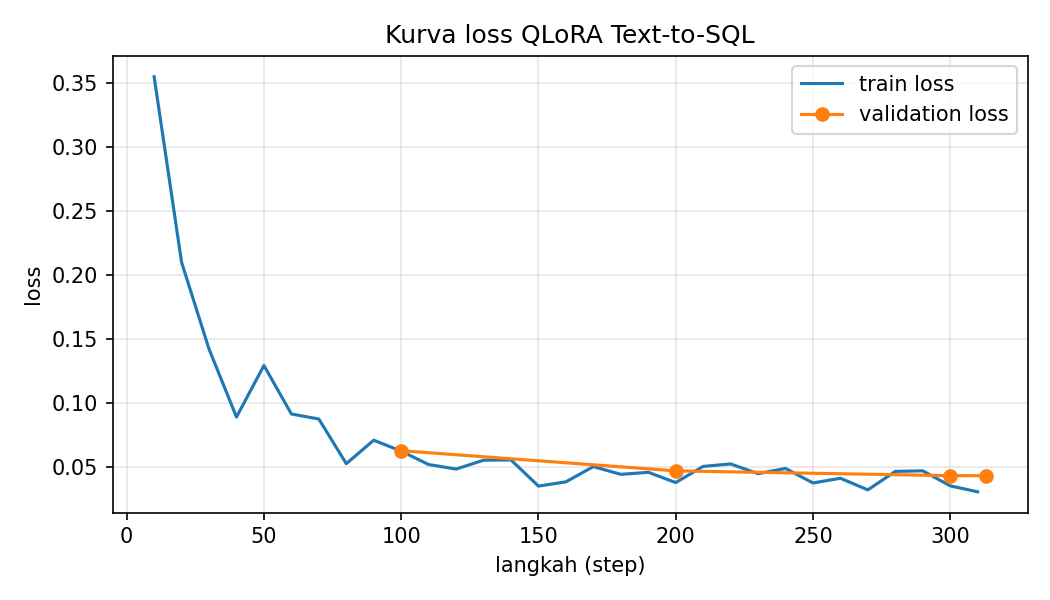

In [9]:
from IPython.display import Image, display

summary = save_log_and_plot(trainer, RES_DIR)
print(summary)
display(Image(str(RES_DIR / "loss_curve.png")))

In [10]:
from eval_utils import get_hf_token

adapter_dir = WORK / "adapter"
model.save_pretrained(str(adapter_dir))
tokenizer.save_pretrained(str(adapter_dir))

hub_id, token = hub_model_id(CONFIG), get_hf_token()
if hub_id and token:
    model.push_to_hub(hub_id, token=token)
    tokenizer.push_to_hub(hub_id, token=token)
    print("Adapter pushed to:", f"https://huggingface.co/{hub_id}")
else:
    print("hf_username/HF_TOKEN empty -> adapter saved locally only at", adapter_dir)

dump_environment(RES_DIR / "environment.txt")   # basis for the pinned requirements.txt
(RES_DIR / "train_summary.json").write_text(json.dumps({**summary, "hub_model_id": hub_id, "config": CONFIG}, indent=2))
print(open(RES_DIR / "environment.txt").read())

Unsloth: Restored added_tokens_decoder metadata in /content/drive/MyDrive/Text2SQL_Dwi-Cahyo-Mariyanto/outputs/adapter/tokenizer_config.json.


README.md:   0%|          | 0.00/1.54k [00:00<?, ?B/s]

Processing Files (0 / 0)      : |          |  0.00B /  0.00B            

New Data Upload               : |          |  0.00B /  0.00B            

  ...adapter_model.safetensors:  13%|#3        | 16.0MB /  120MB            

Validating                    :           |   0%            

... (4 outputs left out)

New Data Upload               : |          |  0.00B /  0.00B            

  ...mp_dr2yf5e/tokenizer.json: 100%|##########| 11.4MB / 11.4MB            

Validating                    :           |   0%            

Adapter pushed to: https://huggingface.co/dwicahyom16/qwen2.5-coder-3b-text2sql-qlora
unsloth==2026.11.9
transformers==5.17.0
trl==1.15.0
peft==0.21.2
torch==2.14.1+cu130
datasets==4.8.5
bitsandbytes==0.50.2
accelerate==1.15.0
gradio==6.31.0
matplotlib==3.10.0



## 7. Quick sanity check on a few validation examples **[GPU]**
The full before-vs-after evaluation is in `03_evaluation.ipynb`.

In [11]:
from eval_utils import generate_sql_batch
from unsloth import FastLanguageModel

FastLanguageModel.for_inference(model)
sample = val[:5]
for r, p in zip(sample, generate_sql_batch(model, tokenizer, sample, batch_size=5)):
    print("Q   :", r["question"]); print("GOLD:", r["answer"]); print("PRED:", p, "\n")

Q   : From what school was the player drafted in round 3?
GOLD: SELECT school FROM table_name_88 WHERE round = 3
PRED: SELECT school FROM table_name_88 WHERE round = 3 

Q   : What is the max pop of 2008 for selfoss?
GOLD: SELECT MAX(population_2008_07_01) FROM table_2252745_1 WHERE administrative_centre = "Selfoss"
PRED: SELECT MAX(population_2008_07_01) FROM table_2252745_1 WHERE administrative_centre = "Selfoss" 

Q   : what are all the pole position where date is 26 july
GOLD: SELECT pole_position FROM table_1137704_2 WHERE date = "26 July"
PRED: SELECT pole_position FROM table_1137704_2 WHERE date = "26 July" 

Q   : What was the original air date of the episode that was directed by Jessica Landaw?
GOLD: SELECT original_air_date FROM table_26824484_1 WHERE directed_by = "Jessica Landaw"
PRED: SELECT original_air_date FROM table_26824484_1 WHERE directed_by = "Jessica Landaw" 

Q   : Which Class has a Frequency MHz larger than 91.7, and a Call sign of k272ec?
GOLD: SELECT class FRO

## Save results
In Colab, a zip archive is downloaded to your computer automatically; on Kaggle it appears in the Output tab after *Save Version*.

In [12]:
from eval_utils import export_results

export_results(RES_DIR)

Results archive: /content/drive/MyDrive/Text2SQL_Dwi-Cahyo-Mariyanto/outputs/text2sql_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

PosixPath('/content/drive/MyDrive/Text2SQL_Dwi-Cahyo-Mariyanto/outputs/text2sql_results.zip')

## 8. Summary
- The adapter is saved in `outputs/adapter` and (if configured) on the Hugging Face Hub.
- Loss curve: `outputs/results/loss_curve.png`; log: `train_log.json`; library versions: `environment.txt`.
- **Next:** `Evaluation_submission/03_evaluation.ipynb` (baseline vs fine-tuned comparison).